Processing subjects:  18%|█▊        | 12/68 [00:00<00:01, 53.31it/s]

Processing subject 037 ...
Processing subject 039 ...
Processing subject 041 ...
Processing subject 055 ...
Processing subject 211 ...
Processing subject 213 ...
Processing subject 216 ...
Processing subject 212 ...
Processing subject 219 ...
Processing subject 220 ...
Processing subject 221 ...
Processing subject 218 ...


Processing subjects:  35%|███▌      | 24/68 [00:03<00:07,  6.16it/s]

Processing subject 222 ...
Subject 218: RESP channel not found.
Subject 219: RESP channel not found.
Processing subject 224 ...
Processing subject 225 ...


Processing subjects:  35%|███▌      | 24/68 [00:20<00:07,  6.16it/s]

Processing subject 226 ...
Processing subject 230 ...
Processing subject 231 ...
Processing subject 237 ...
Processing subject 240 ...
Processing subject 248 ...
Processing subject 252 ...
Processing subject 253 ...
Processing subject 254 ...


... (4 outputs left out)

Processing subjects:  71%|███████   | 48/68 [01:40<00:53,  2.67s/it]

Processing subject 410 ...
Processing subject 411 ...
Processing subject 413 ...
Processing subject 414 ...
Processing subject 415 ...
Processing subject 417 ...
Processing subject 418 ...
Processing subject 427 ...
Processing subject 430 ...
Processing subject 437 ...
Processing subject 438 ...
Processing subject 439 ...


Processing subjects: 100%|██████████| 68/68 [02:12<00:00,  1.95s/it]


Processing subject 442 ...
Processing subject 443 ...
Processing subject 444 ...
Processing subject 446 ...
Processing subject 449 ...
Processing subject 451 ...
Processing subject 452 ...
Processing subject 453 ...
Processing subject 454 ...
Processing subject 456 ...
Processing subject 466 ...
Subject 453: RESP channel not found.
Subject 454: RESP channel not found.
Processing subject 471 ...
Processing subject 472 ...
Subject 456: RESP channel not found.
Processing subject 474 ...
Processing subject 476 ...
Processing subject 477 ...
Processing subject 480 ...
Processing subject 482 ...
Subject 480: RESP channel not found.
Processing subject 484 ...
Subject 477: RESP channel not found.
Processing subject 485 ...
Subject 482: RESP channel not found.
Subject 484: RESP channel not found.
Subject 485: RESP channel not found.


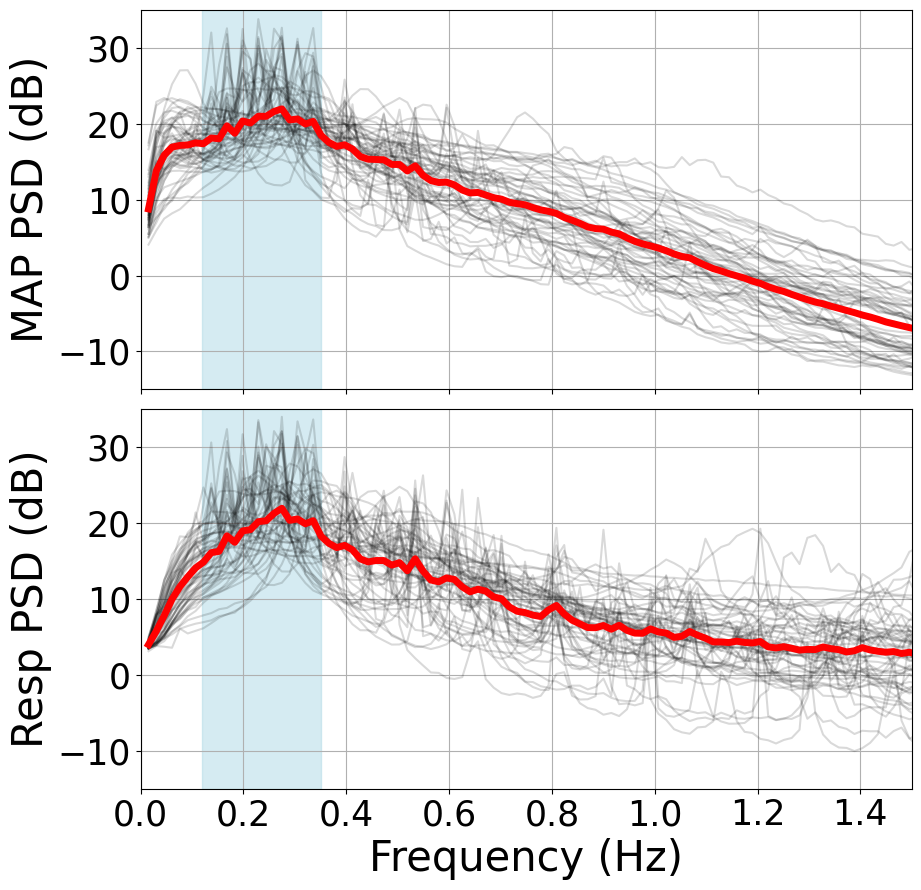

In [2]:
import os

import matplotlib.pyplot as plt
import numpy as np
import wfdb
from joblib import Parallel, delayed
from tqdm import tqdm
from utils import pwelch

fs = 125                        # Sampling frequency
nfft = 2 ** 13                  # Number of FFT points
noverlap = int(nfft * 0.8)      # 80% overlap
window = np.ones(nfft)          # Rectangular window for PSD calculation

data_dir = '../../../../../../data/physionet.org/files/mimicdb/1.0.0'
env_dir = '../results/envelopes'
fig_dir = '../figures'
os.makedirs(fig_dir, exist_ok=True)
files = sorted(os.listdir(env_dir))
subjects = [file.split('.')[0] for file in files if file.endswith('.npz')]

def interpolate_nan(x):
    """
    Interpolates NaN values in a 1D array using linear interpolation used for respiration signal
    """
    x = np.asarray(x, dtype=float).squeeze()
    valid = np.isfinite(x)
    sample_indices = np.arange(len(x))
    x[~valid] = np.interp(sample_indices[~valid], sample_indices[valid], x[valid])
    return x


def process_subject(subject, env_dir, window, noverlap, nfft):
    print(f'Processing subject {subject} ...')
    path = f'{data_dir}/{subject}/{subject}'
    signals, metadata = wfdb.rdsamp(path)
    channel_names = metadata['sig_name']
    if channel_names is None or 'RESP' not in channel_names:
        print(f'Subject {subject}: RESP channel not found.')
        return None
    resp_channel = channel_names.index('RESP')
    resp = signals[:, resp_channel]

    path = f'{env_dir}/{subject}.npz'
    data = np.load(path)
    env_u = data['env_u']
    env_d = data['env_d']

    n_samples = min(len(resp), len(env_u), len(env_d))
    resp = resp[:n_samples]
    env_u = env_u[:n_samples]
    env_d = env_d[:n_samples]
    resp = interpolate_nan(resp)
    mp = interpolate_nan((env_u + env_d) / 2.0)

    psd_resp = pwelch(resp, window=window, noverlap=noverlap, nfft=nfft)
    psd_mp = pwelch(mp, window=window, noverlap=noverlap, nfft=nfft)

    return subject, psd_mp, psd_resp


# Run in parallel
results = Parallel(n_jobs=-1)(delayed(process_subject)(subject, env_dir, window, noverlap, nfft) for subject in tqdm(subjects, desc='Processing subjects'))
results = [result for result in results if result is not None]
valid_subjects = [result[0] for result in results]
PSD_mp = np.array([result[1] for result in results])
PSD_resp = np.array([result[2] for result in results])

# Convert PSDs to dB
freqs = np.fft.fftfreq(nfft, d=1 / fs)
PSD_mp_db = 10 * np.log10(PSD_mp + np.finfo(float).eps)
PSD_resp_db = 10 * np.log10(PSD_resp + np.finfo(float).eps)
Pxx_mp_avg = np.mean(PSD_mp_db, axis=0)
Pxx_resp_avg = np.mean(PSD_resp_db, axis=0)

#%%
FIG_SIZE = (9.5, 9)
XLABEL_FONT_SIZE = 30
YLABEL_FONT_SIZE = 30
XTICK_FONT_SIZE = 25
YTICK_FONT_SIZE = 25
SUBJECT_LINE_COLOR = 'black'
SUBJECT_LINE_ALPHA = 0.15
AVERAGE_LINE_COLOR = 'red'
AVERAGE_LINE_WIDTH = 5
FREQ_RANGE = (0, 1.5)
MAP_PSD_RANGE = (-15, 35)
RESP_PSD_RANGE = (-15, 35)
HIGHLIGHT_RANGE = (0.12, 0.35)
HIGHLIGHT_COLOR = 'lightblue'
HIGHLIGHT_ALPHA = 0.5


fig, axes = plt.subplots(nrows=2, ncols=1, figsize=FIG_SIZE, sharex=True)

# MAP PSD
axes[0].axvspan(HIGHLIGHT_RANGE[0], HIGHLIGHT_RANGE[1], color=HIGHLIGHT_COLOR, alpha=HIGHLIGHT_ALPHA, zorder=0)
for i in range(len(PSD_mp)):
    axes[0].plot(freqs[1:nfft // 2], PSD_mp_db[i, 1:], color=SUBJECT_LINE_COLOR, alpha=SUBJECT_LINE_ALPHA)

axes[0].plot(freqs[1:nfft // 2], Pxx_mp_avg[1:], color=AVERAGE_LINE_COLOR, lw=AVERAGE_LINE_WIDTH)
axes[0].set_xlim(FREQ_RANGE)
axes[0].set_ylim(MAP_PSD_RANGE)
axes[0].set_ylabel('MAP PSD (dB)', fontsize=YLABEL_FONT_SIZE)
axes[0].tick_params(axis='y', labelsize=YTICK_FONT_SIZE)
axes[0].grid(True)

# Respiration PSD
axes[1].axvspan(HIGHLIGHT_RANGE[0], HIGHLIGHT_RANGE[1], color=HIGHLIGHT_COLOR, alpha=HIGHLIGHT_ALPHA, zorder=0)
for i in range(len(PSD_resp)):
    axes[1].plot(freqs[1:nfft // 2], PSD_resp_db[i, 1:], color=SUBJECT_LINE_COLOR, alpha=SUBJECT_LINE_ALPHA)

axes[1].plot(freqs[1:nfft // 2], Pxx_resp_avg[1:], color=AVERAGE_LINE_COLOR, lw=AVERAGE_LINE_WIDTH)
axes[1].set_xlim(FREQ_RANGE)
axes[1].set_ylim(RESP_PSD_RANGE)
axes[1].set_xlabel('Frequency (Hz)', fontsize=XLABEL_FONT_SIZE)
axes[1].set_ylabel('Resp PSD (dB)', fontsize=YLABEL_FONT_SIZE)
axes[1].tick_params(axis='x', labelsize=XTICK_FONT_SIZE)
axes[1].tick_params(axis='y', labelsize=YTICK_FONT_SIZE)
axes[1].grid(True)

fig.align_ylabels(axes)
plt.subplots_adjust(hspace=0.07)
plt.tight_layout(rect=[0.05, 0, 1, 1])

path = f'{fig_dir}/psd.png'
plt.savefig(path, dpi=300)
plt.show()